# 02 · Modélisation et sélection sans accès au test
## Protocole
Quatre familles : baseline majoritaire, régression logistique, arbre, Random Forest. Les scores sont calculés en **5 plis stratifiés externes**. Pour les versions réglées, une recherche en **3 plis internes**, optimisant l'Average Precision, est répétée dans chaque pli externe : la ligne évaluée ne participe pas au réglage.

Le seuil et la famille sont ensuite sélectionnés sur les prédictions hors-pli du train selon le coût et les contraintes métier. Ces scores de sélection ne sont pas une estimation indépendante de la politique finale ; celle-ci sera évaluée une seule fois sur le test au notebook 03.

**AP** désigne `average_precision_score`, une synthèse de la courbe précision-rappel (pas l'aire trapézoïdale). Le rappel est le critère métier principal ; l'AP sert au réglage du classement des risques. Les scores F1 affichés utilisent le seuil 0,5.

## Guide de lecture
**Question :** quel modèle et quel seuil donnent le meilleur compromis entre pannes manquées et inspections inutiles ?

1. Construire les pipelines et les configurations.
2. Comparer leurs scores en validation croisée, sans utiliser le test.
3. Illustrer le danger de la fuite par les modes de panne.
4. Choisir le seuil selon le coût et les contraintes métier.
5. Geler le choix dans `results/selection.json`.

**À savoir à l'oral :** la validation interne règle les hyperparamètres ; la validation externe produit les prédictions hors-pli. Le test reste réservé jusqu'au notebook 03.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd() if (Path.cwd() / 'src/project.py').exists() else Path.cwd().parent
assert (ROOT / 'src/project.py').exists(), 'Ouvrir depuis la racine du projet ou notebooks/.'
sys.path.insert(0, str(ROOT / 'src'))
from project import *
RESULTS = ROOT / 'results'
FIGURES = RESULTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.spines.top':False, 'axes.spines.right':False, 'figure.dpi':110})
pd.set_option('display.max_columns', 25)
def savefig(name):
    plt.tight_layout()
    plt.savefig(FIGURES / name, dpi=150, bbox_inches='tight')
    plt.show()

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
import joblib

df = load_data()
train_idx, _ = split_indices(df)
X = df.iloc[train_idx][FEATURES].reset_index(drop=True)
y = df.iloc[train_idx].machine_failure.reset_index(drop=True)
outer = StratifiedKFold(5,shuffle=True,random_state=SEED)
inner = StratifiedKFold(3,shuffle=True,random_state=SEED+1)
models = {
 'Baseline': (DummyClassifier(strategy='most_frequent'),None),
 'Logistique': (LogisticRegression(max_iter=2000,class_weight='balanced',random_state=SEED),None),
 'Arbre': (DecisionTreeClassifier(random_state=SEED),None),
 'Random Forest': (RandomForestClassifier(n_estimators=100,random_state=SEED,n_jobs=1),None),
 'Logistique réglée': (LogisticRegression(max_iter=2000,class_weight='balanced',random_state=SEED),{'model__C':[.1,1,10]}),
 'Arbre réglé': (DecisionTreeClassifier(class_weight='balanced',random_state=SEED),{'model__max_depth':[4,8,None],'model__min_samples_leaf':[5,20]}),
 'Random Forest réglée': (RandomForestClassifier(n_estimators=100,class_weight='balanced',random_state=SEED,n_jobs=1),{'model__max_depth':[10,None],'model__min_samples_leaf':[1,5]})}


In [2]:
fold_rows, oof = [], {}
for name,(base,grid) in models.items():
    p = np.full(len(y),np.nan)
    for fold,(it,iv) in enumerate(outer.split(X,y),1):
        pipe = make_pipeline(clone(base))
        est = GridSearchCV(pipe,grid,cv=inner,scoring='average_precision',n_jobs=2) if grid else pipe
        est.fit(X.iloc[it],y.iloc[it])
        p[iv] = est.predict_proba(X.iloc[iv])[:,1]
        val = metrics(y.iloc[iv],p[iv])
        tr = metrics(y.iloc[it],est.predict_proba(X.iloc[it])[:,1])
        fold_rows.append({'model':name,'fold':fold,'train_f1':tr['f1'],'val_f1':val['f1'],'val_recall':val['recall'],'val_precision':val['precision'],'val_ap':val['ap']})
    assert np.isfinite(p).all()
    oof[name]=p
    print(name, 'terminé', flush=True)

Baseline terminé
Logistique terminé
Arbre terminé
Random Forest terminé
Logistique réglée terminé
Arbre réglé terminé
Random Forest réglée terminé


### Comparaison des modèles à seuil 0,5
Les scores ci-dessous proviennent exclusivement des plis de validation externes.

In [3]:
fold_scores=pd.DataFrame(fold_rows)
summary=fold_scores.groupby('model',sort=False).agg({c:['mean','std'] for c in ['train_f1','val_f1','val_recall','val_precision','val_ap']})
# Tableau compact : moyenne ± écart-type entre les cinq plis externes.
readable = pd.DataFrame(index=summary.index)
for metric,label in [('train_f1','F1 train'),('val_f1','F1 validation'),('val_recall','Rappel'),('val_precision','Précision'),('val_ap','AP')]:
    readable[label] = [f"{m:.3f} ± {s:.3f}" for m,s in zip(summary[(metric,'mean')],summary[(metric,'std')])]
display(readable)
readable.to_csv(RESULTS/'comparaison_lisible.csv')
fold_scores.to_csv(RESULTS/'cv_folds.csv',index=False)
summary.to_csv(RESULTS/'cv_summary.csv')
pd.DataFrame(oof).assign(target=y,source_index=train_idx).to_csv(RESULTS/'oof_predictions.csv',index=False)

,F1 train,F1 validation,Rappel,Précision,AP
model,,,,,
Baseline,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.034 ± 0.000
Logistique,0.275 ± 0.009,0.271 ± 0.012,0.841 ± 0.051,0.162 ± 0.009,0.459 ± 0.047
Arbre,1.000 ± 0.000,0.826 ± 0.029,0.830 ± 0.031,0.823 ± 0.043,0.689 ± 0.046
Random Forest,1.000 ± 0.000,0.889 ± 0.032,0.819 ± 0.048,0.974 ± 0.018,0.896 ± 0.027
Logistique réglée,0.269 ± 0.006,0.267 ± 0.015,0.838 ± 0.051,0.159 ± 0.009,0.486 ± 0.029
Arbre réglé,0.627 ± 0.042,0.550 ± 0.035,0.897 ± 0.069,0.398 ± 0.036,0.810 ± 0.084
Random Forest réglée,0.997 ± 0.002,0.856 ± 0.034,0.771 ± 0.040,0.963 ± 0.031,0.888 ± 0.028


**Lecture :** comparer F1 train et validation révèle le surapprentissage ; l'écart-type mesure la variabilité entre plis, pas un intervalle de confiance. La baseline ne détecte aucune panne. Les versions réglées peuvent perdre du F1 à 0,5 tout en offrant un meilleur compromis une fois le seuil adapté.

In [4]:
# Démonstration pédagogique, exclue de tous les choix : fuite via modes de panne.
leak_X = df.iloc[train_idx][MODES].reset_index(drop=True)
leak_p = cross_val_predict(DecisionTreeClassifier(random_state=SEED),leak_X,y,cv=outer,method='predict_proba')[:,1]
leak_table=pd.DataFrame([{'configuration':'Modes de panne (interdit)',**metrics(y,leak_p)}, {'configuration':'Capteurs physiques (arbre)',**metrics(y,oof['Arbre'])}])
display(leak_table[['configuration','recall','precision','f1','ap']])
leak_table.to_csv(RESULTS/'audit_fuite.csv',index=False)

,configuration,recall,precision,f1,ap
0,Modes de panne (interdit),0.974170,1.000000,0.986916,0.975345
1,Capteurs physiques (arbre),0.830258,0.821168,0.825688,0.687531


Les scores avec les modes de panne ne représentent pas une prédiction utilisable : ils exploitent le diagnostic de l'événement. Même s'ils ne sont pas parfaits (incohérences documentées au notebook 01), ces champs doivent rester exclus.

## Matrice de coûts et choix du seuil
Hypothèses pédagogiques, reprises du diaporama : **FN = 3 000 €**, **FP = 150 €**, **TP = 500 €**, **TN = 0 €**. Le coût TP couvre l'intervention efficace ; les 150 € couvrent une vérification inutile. On ne facture pas 500 € supplémentaires aux faux positifs. Ces montants et l'efficacité des interventions doivent être mesurés au pilote.

`coût = 3000 × FN + 150 × FP + 500 × TP`. On cherche le coût minimum sous rappel ≥ 0,80 et précision ≥ 1/3. Le test ne participe pas au choix.

Contraintes satisfaites sur le train hors-pli : True


,Choix gelé
model,Random Forest
threshold,0.17
tn,7641
fp,88
fn,36
tp,235
recall,0.867159
precision,0.727554
f1,0.791246
ap,0.895292


,model,threshold,tn,fp,fn,tp,recall,precision,f1,ap,accuracy,cost,feasible
304,Random Forest,0.05,7330,399,21,250,0.922509,0.385208,0.543478,0.895292,0.947500,247850.0,True
319,Random Forest,0.20,7656,73,40,231,0.852399,0.759868,0.803478,0.895292,0.985875,246450.0,True
349,Random Forest,0.50,7723,6,49,222,0.819188,0.973684,0.889780,0.895292,0.993125,258900.0,True
316,Random Forest,0.17,7641,88,36,235,0.867159,0.727554,0.791246,0.895292,0.984500,238700.0,True


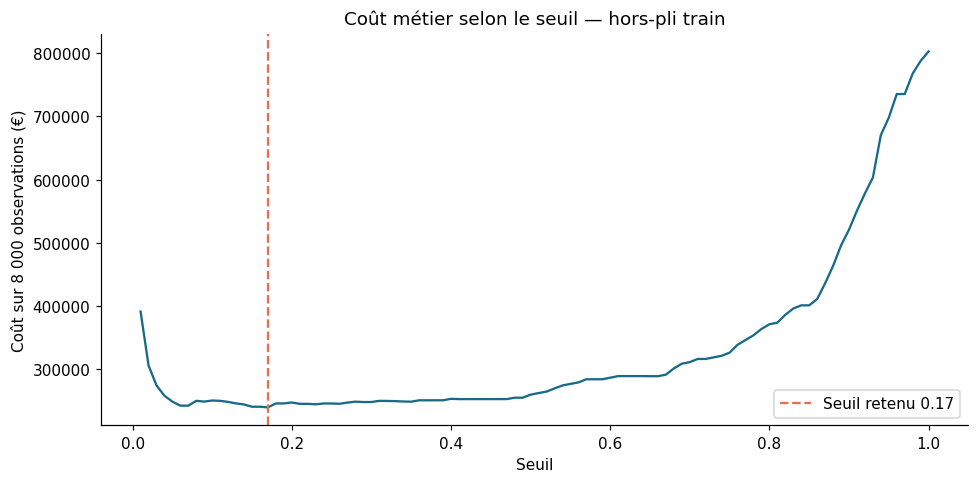

In [5]:
thresholds=np.unique(np.r_[np.arange(.01,1.,.01),1.0])
rows=[]
for name,p in oof.items():
    for threshold in thresholds:
        rows.append({'model':name,'threshold':float(threshold),**metrics(y,p,threshold)})
search=pd.DataFrame(rows)
search['feasible']=(search.recall>=.80)&(search.precision>=1/3)
feasible=search[search.feasible]
# Aucun succès artificiellement imposé si les contraintes ne sont pas atteintes.
pool=feasible if len(feasible) else search
selected=pool.sort_values(['cost','recall','precision','model','threshold'],ascending=[True,False,False,True,False]).iloc[0]
name=selected['model']; threshold=float(selected.threshold)
print('Contraintes satisfaites sur le train hors-pli :', bool(selected.feasible))
display(selected.to_frame('Choix gelé'))
chosen_curve=search[search.model==name]
display(chosen_curve.iloc[[int(np.argmin(abs(chosen_curve.threshold-t))) for t in [.05,.2,.5,threshold]]].drop_duplicates())
search.to_csv(RESULTS/'threshold_search.csv',index=False)
plt.plot(chosen_curve.threshold,chosen_curve.cost,color='#176B87')
plt.axvline(threshold,color='#E76F51',linestyle='--',label=f'Seuil retenu {threshold:.2f}')
plt.xlabel('Seuil'); plt.ylabel('Coût sur 8 000 observations (€)'); plt.title('Coût métier selon le seuil — hors-pli train'); plt.legend()
savefig('04_cout_seuil.png')

In [6]:
# Réglage final sur tout le train ; toujours aucun accès au test.
base,grid=models[name]
pipe=make_pipeline(clone(base))
final=GridSearchCV(pipe,grid,cv=inner,scoring='average_precision',n_jobs=2) if grid else pipe
final.fit(X,y)
final_model=final.best_estimator_ if grid else final
params=final.best_params_ if grid else {}
joblib.dump(final_model,RESULTS/'final_model.joblib')
selection={'model':name,'threshold':threshold,'params':params,'oof_metrics':metrics(y,oof[name],threshold),'constraints_oof_met':bool(selected.feasible),'seed':SEED,'test_fraction':.2}
(RESULTS/'selection.json').write_text(json.dumps(selection,indent=2,ensure_ascii=False),encoding='utf-8')
print('Modèle et seuil gelés :',name,threshold,params)
assert list(final_model.named_steps)==['physics','prep','model']

Modèle et seuil gelés : Random Forest 0.17 {}


## Bilan
Le modèle et le seuil sont sauvegardés. Le notebook 03 charge ces choix sans réoptimisation. Les probabilités de modèles pondérés ne sont pas des probabilités calibrées ; le seuil est un paramètre opérationnel empirique. La validation synthétique ne démontre ni préavis à 24 h ni économies causales en production.

In [7]:
display(Markdown(
    f"### Choix retenu avant ouverture du test\n"
    f"**{selection['model']}**, seuil **{selection['threshold']:.2f}**. "
    f"Sur les prédictions hors-pli du train : rappel **{selection['oof_metrics']['recall']:.1%}**, "
    f"précision **{selection['oof_metrics']['precision']:.1%}**, "
    f"coût **{selection['oof_metrics']['cost']:,.0f} €**.\n\n"
    "Ces chiffres servent à sélectionner le modèle. Les performances finales seront celles du notebook 03."
))

### Choix retenu avant ouverture du test
**Random Forest**, seuil **0.17**. Sur les prédictions hors-pli du train : rappel **86.7%**, précision **72.8%**, coût **238,700 €**.

Ces chiffres servent à sélectionner le modèle. Les performances finales seront celles du notebook 03.